# 03｜二值化与形态学

目标：把真实照片变成黑白前景，理解阈值和形态学会怎样改变细小结构。白色表示算法当前选中的像素，**不自动等于缺陷、镍片或已焊**。

参考：[OpenCV 阈值](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html)、[形态学](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html)。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lab_utils.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import lab_utils as lab
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.12.0 | NumPy 2.2.6


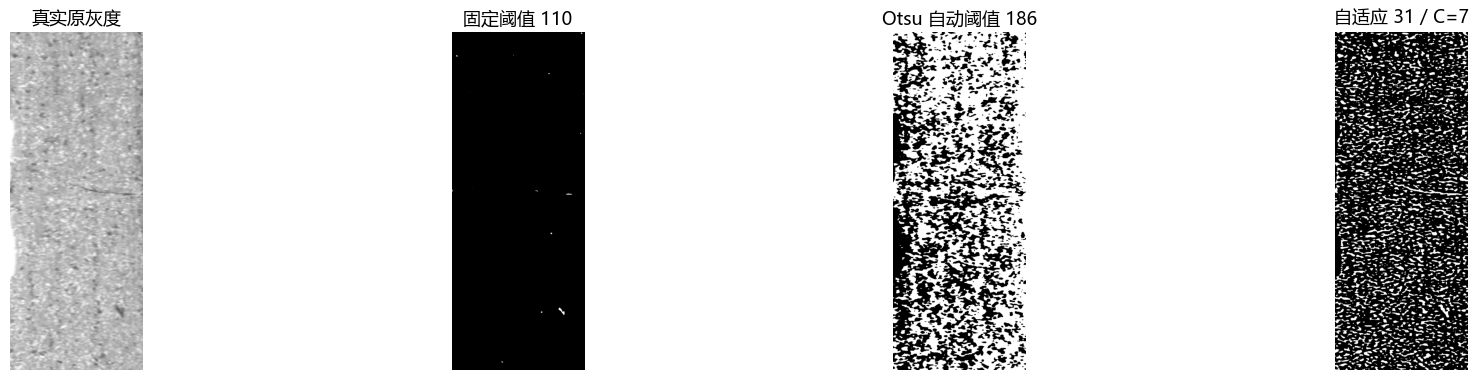

In [2]:
g = lab.load_case("kolektor_defect_0", grayscale=True)
smooth = cv2.GaussianBlur(g, (5, 5), 0)
_, fixed = cv2.threshold(smooth, 110, 255, cv2.THRESH_BINARY_INV)
otsu_value, otsu = cv2.threshold(smooth, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
adaptive = cv2.adaptiveThreshold(smooth, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY_INV, 31, 7)
lab.show_images([g, fixed, otsu, adaptive],
                ["真实原灰度", "固定阈值 110", f"Otsu 自动阈值 {otsu_value:.0f}", "自适应 31 / C=7"], cols=4)

## 1. 三种阈值的适用条件

固定阈值需要亮度稳定；Otsu 根据全图灰度分布选阈值，前景背景难分时也会失败；自适应阈值根据局部邻域判断，可能同时抓出划痕、噪声和原有纹理。`blockSize` 要是大于 1 的奇数。

现在改变同一张实拍照片的亮度，观察固定阈值漂移。下方是派生挑战，不是新的照片或独立准确率测试。

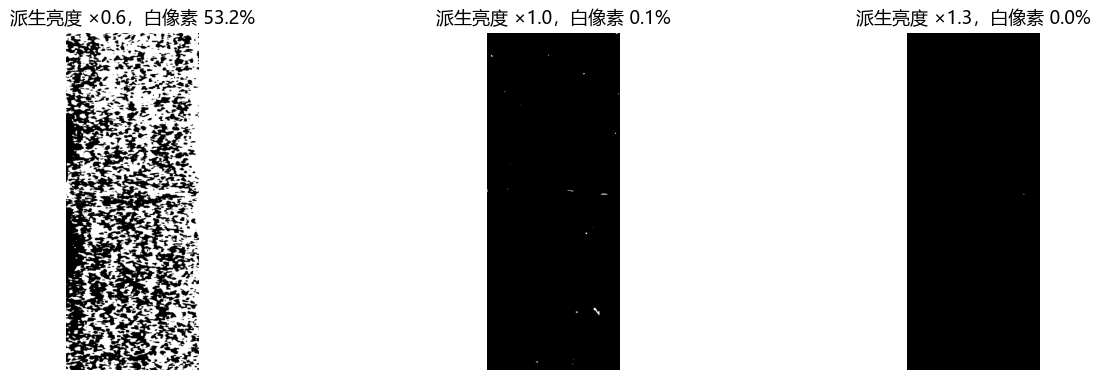

In [3]:
samples, titles = [], []
for factor in [0.6, 1.0, 1.3]:
    derived = lab.degrade(g, factor)
    _, mask = cv2.threshold(derived, 110, 255, cv2.THRESH_BINARY_INV)
    samples.append(mask); titles.append(f"派生亮度 ×{factor}，白像素 {np.mean(mask > 0):.1%}")
lab.show_images(samples, titles, cols=3)

## 2. 开闭运算是“修改形状”

开运算先腐蚀后膨胀，常移除小白点，也会删掉细裂纹。闭运算先膨胀后腐蚀，常连上断开的白线，也会把相邻零件粘在一起。核大小必须和原图像素尺度一起记录，不能在缩放后不变地沿用。

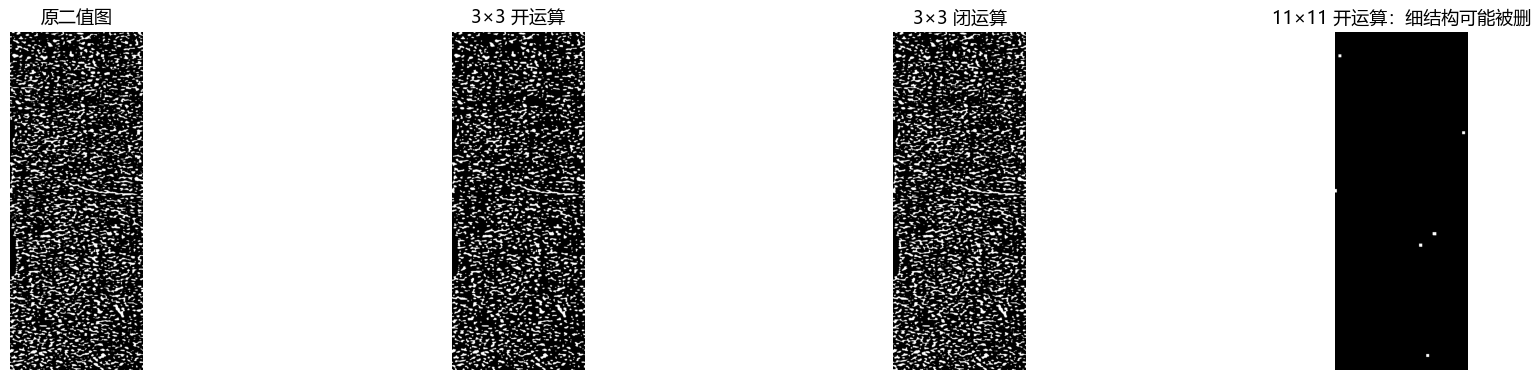

In [4]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
opened = cv2.morphologyEx(adaptive, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(adaptive, cv2.MORPH_CLOSE, kernel)
big_open = cv2.morphologyEx(adaptive, cv2.MORPH_OPEN, np.ones((11, 11), np.uint8))
lab.show_images([adaptive, opened, closed, big_open],
                ["原二值图", "3×3 开运算", "3×3 闭运算", "11×11 开运算：细结构可能被删"], cols=4)
assert set(np.unique(opened)).issubset({0, 255})

## 对照真实标注，而不是凭处理图下结论

掩膜来自上游人工标注，仅作观察参考。下图不把掩膜送给算法，也不以本课六张示例调出一个“已验收阈值”。

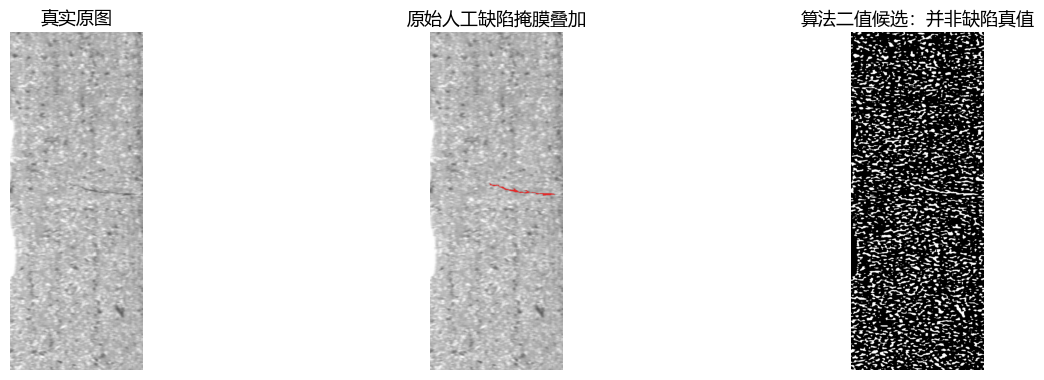

In [5]:
truth = lab.load_case("kolektor_defect_0_mask", grayscale=True)
image = cv2.cvtColor(g, cv2.COLOR_GRAY2BGR)
overlay = image.copy(); overlay[truth > 0] = (40, 40, 230)
lab.show_images([image, overlay, adaptive],
                ["真实原图", "原始人工缺陷掩膜叠加", "算法二值候选：并非缺陷真值"], cols=3)

## 来源与练习边界

公开焊缝：sukmaadhiwijaya / rikkarth，固定提交 `8b80d1afe88c0b946500a498cbdb9d7a1eda5533`，数据卡声明 CC0-1.0；工业表面：Kolektor Group / ViCoS，CC BY-NC-SA 4.0；分散零件：Tung1213，CC BY-SA 3.0；重叠零件：Technologyfelix，CC BY-SA 4.0。相关照片和派生图保留原许可及署名。

完整来源、原许可页、下载路径及 SHA256 见 [DATA_SOURCES.md](../DATA_SOURCES.md) 和 [source_manifest.json](../sources/source_manifest.json)。本课是非商业教学。灰度、二值、叠框及扰动均为原照片的派生图，七格合成图另有醒目标记。它们不等于新增独立验收数据，也不证明电池焊接准确率或机械强度。